In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## dataset-composition

**Figure 1: Composition of the instruction-tuning dataset by source.** Web forums and textbooks together make up 62% of the 1.24M examples.

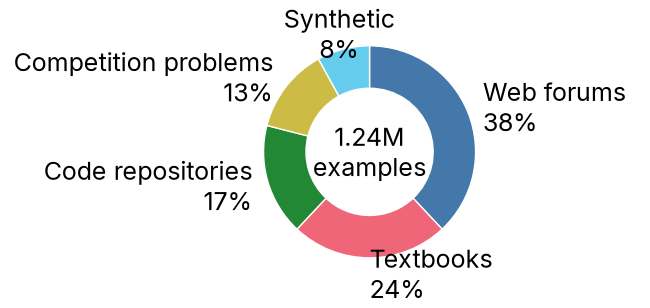

In [2]:
with open("../dataset-composition.json") as f:
    data = json.load(f)

sources = sorted(data["sources"].items(), key=lambda item: item[1], reverse=True)
shares = [share for _, share in sources]
series_colors = [colors[f"series-{i + 1}"] for i in range(len(sources))]

fig, ax = plt.subplots(figsize=(3.25, 3.25))
wedges, labels = ax.pie(
    shares,
    colors=series_colors,
    labels=[f"{name}\n{share:.0%}" for name, share in sources],
    labeldistance=1.15,
    textprops=dict(fontsize=9),
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.4, edgecolor="white", linewidth=0.5),
)
# the last part sits just left of 12 o'clock; centering its label keeps it clear of its neighbour's
labels[-1].set_ha("center")
ax.text(0, 0, f"{data['total_examples'] / 1e6:.2f}M\nexamples", ha="center", va="center", fontsize=9)

fit_height(fig, ax)
fig.savefig("dataset-composition.pdf")
fig.savefig("dataset-composition.png")
plt.show()